# 주요변수 범용 예측모델 설계 (개정) — H=4, 변수별 변환, CRPS

## 배경

3번 노트북의 한계(비현실적 구간, Winkler의 한계, 시불변 오차폭 가정)를
**변수별 변환(로그/로짓) + H 7→4 + CRPS·Likelihood 결합(Borda)**으로 개선한다.

## 목적

1-1 변환 확정 / 1-2 H=4 백테스트 / 1-3 정규성+파워체크 / 1-4 CRPS+Likelihood
비교 / 1-5 ARCH-LM / 1-6 역변환+편향보정

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from scipy import stats
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1",
    "X2": "X2",
    "X3_l1": "X3",
    "X4": "X4",
    "X5_l1": "X5",
    "X6_l1": "X6",
}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")  # 노트북 실행 cwd는 notebooks/ 폴더 기준
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}
var_std = {c: series[c].std() for c in COLS}

H = 4           # 예측 horizon: 7 -> 4분기로 축소
MIN_TRAIN = 20  # 백테스트 origin 시작 전 최소 학습 길이
LAG = 2         # 회귀/트리 계열이 쓰는 AR lag 차수
INITIAL_CALIB = 15  # walk-forward calibration 최소 확보 개수

def rng_for(name):
    """모델 이름 기반 고정 시드 -- 다른 모델을 넣고 빼도, 순서가 바뀌어도
    이 모델 자신의 무작위 리샘플링 결과는 항상 똑같다(순서의존성 제거, 4-1과 동일 방식)."""
    return np.random.default_rng(int.from_bytes(name.encode(), "little") % (2**32))

for c in COLS:
    print(f"{LABELS[c]}: n={len(series[c])}")


X1: n=59
X2: n=60
X3: n=60
X4: n=60
X5: n=59
X6: n=63


## 1-1. 변수별 변환 확정

| 변수 | 역대 범위 | 변환 | 이유 |
|---|---|---|---|
| X3 | [79.2, 1305.8] | **로그** | 물리적 합 — 음수 불가능 |
| X6 | [0.569, 0.647] | **로짓** | 비율(0~1) |
| 나머지 4개 | — | 없음 | 구조적 하한 없음 |

**원칙**: 변환은 모델링에만, 평가는 항상 원래 스케일에서.

In [2]:
def identity(x): return x
def log_fwd(x): return np.log(x)
def log_inv(x): return np.exp(x)
def logit_fwd(p): return np.log(p / (1 - p))
def logit_inv(z): return 1 / (1 + np.exp(-z))

# 로그/로짓 변환의 로그-야코비안 (predictive likelihood 계산용: f_Y(y) = f_Z(g(y)) * |g'(y)|)
def logjac_identity(y): return np.zeros_like(y)
def logjac_log(y): return -np.log(y)
def logjac_logit(y): return -np.log(y) - np.log(1 - y)

TRANSFORMS = {
    "X3_l1": (log_fwd, log_inv, logjac_log, "로그"),
    "X6_l1": (logit_fwd, logit_inv, logjac_logit, "로짓"),
}
DEFAULT_TRANSFORM = (identity, identity, logjac_identity, "없음")

for c in COLS:
    _, _, _, name = TRANSFORMS.get(c, DEFAULT_TRANSFORM)
    print(f"{LABELS[c]}: {name}")


X1: 없음
X2: 없음
X3: 로그
X4: 없음
X5: 없음
X6: 로짓


## 1-2. 모델 정의 및 H=4 확장윈도우 백테스트

3번과 동일한 5개 계열을 H=4로 줄이고 변환 적용. 오차(`err_t`)는 변환공간에,
실제값(`actual_orig`)은 원래 스케일로 저장한다.

In [3]:
def fc_naive(values, h=H):
    return np.repeat(values[-1], h)

def fc_auto_arima(values, h=H):
    try:
        model = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore")
        return np.asarray(model.predict(n_periods=h))
    except Exception:
        return fc_naive(values, h)

def _lag_xy(values, lag=LAG):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)

def fc_ols(values, h=H):
    return _recursive_forecast(lambda X, y: LinearRegression().fit(X, y), values, h)

def fc_gbm(values, h=H):
    return _recursive_forecast(
        lambda X, y: GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=0).fit(X, y),
        values, h,
    )

def fc_gp(values, h=H):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean

MODELS = {"naive": fc_naive, "auto_arima": fc_auto_arima, "ols_lag": fc_ols, "gbm_lag": fc_gbm, "gp": fc_gp}
FAMILY_LABELS = {
    "naive": "baseline (naive)", "auto_arima": "시계열 (Auto-ARIMA)", "ols_lag": "회귀 (선형회귀)",
    "gbm_lag": "트리기반 (GBM)", "gp": "커널/비모수 (GP)",
}
print("모델 5개 정의 완료:", list(MODELS.keys()))


모델 5개 정의 완료: ['naive', 'auto_arima', 'ols_lag', 'gbm_lag', 'gp']


In [4]:
t0 = time.time()
records = []
for c in COLS:
    fwd, inv, logjac, _ = TRANSFORMS.get(c, DEFAULT_TRANSFORM)
    vals_orig = series[c]
    vals_t = fwd(vals_orig)
    n = len(vals_orig)
    for origin in range(MIN_TRAIN, n - H + 1):
        train_t, actual_orig = vals_t[:origin], vals_orig[origin:origin + H]
        actual_t = fwd(actual_orig)
        for name, fn in MODELS.items():
            try:
                fc_t = fn(train_t, H)
            except Exception:
                fc_t = np.repeat(train_t[-1], H)
            err_t = actual_t - fc_t
            for h in range(1, H + 1):
                records.append({
                    "var": c, "model": name, "origin": origin, "h": h,
                    "err_t": err_t[h - 1], "fc_t": fc_t[h - 1], "actual_orig": actual_orig[h - 1],
                })
    print(f"{LABELS[c]} 완료 ({time.time()-t0:.0f}초 경과)")

err_df = pd.DataFrame(records)
print(f"총 소요시간: {time.time()-t0:.0f}초, 총 {len(err_df)}개 오차 기록")
print(f"참고: H=7일 때 origin은 변수당 33~37개였는데, H=4로는 {err_df.groupby('var')['origin'].nunique().min()}~{err_df.groupby('var')['origin'].nunique().max()}개로 늘었다.")


X1 완료 (15초 경과)


X2 완료 (49초 경과)


X3 완료 (139초 경과)


X4 완료 (205초 경과)


X5 완료 (232초 경과)


X6 완료 (274초 경과)
총 소요시간: 274초, 총 4460개 오차 기록
참고: H=7일 때 origin은 변수당 33~37개였는데, H=4로는 36~40개로 늘었다.


## 1-3. 잔차 정규성 점검 (CRPS 도입 전 게이트)

Auto-ARIMA 잔차로 정규성을 확인한다(Shapiro-Wilk, QQ-plot). horizon별
표준화(z=err_t/sigma_h) 후 검정한다.

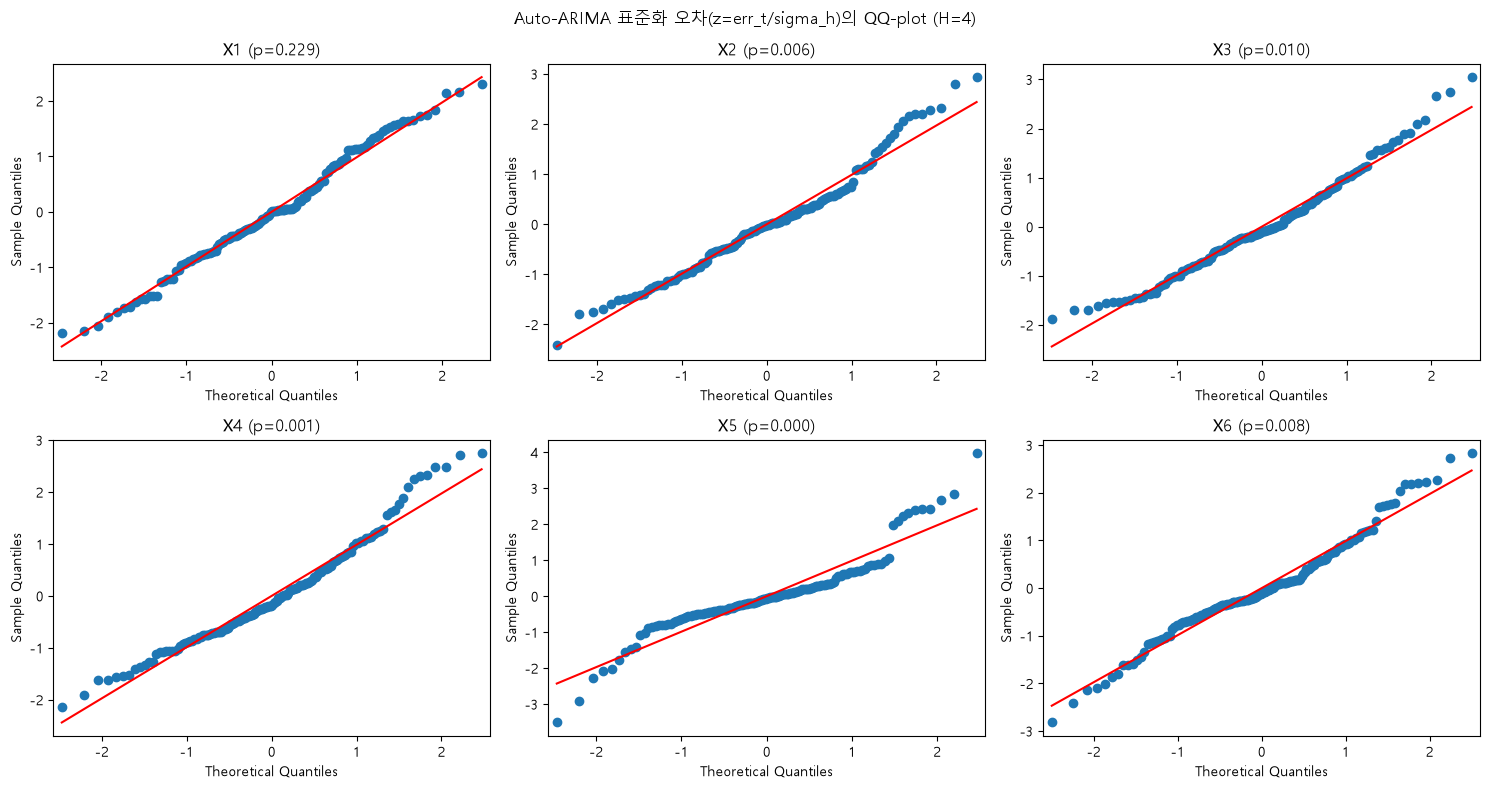

,n,Shapiro-Wilk p-value,정규성 기각(5%)
변수,,,
X1,144,0.2290,아니오
X2,148,0.0062,예
X3,148,0.0101,예
X4,148,0.0012,예
X5,144,0.0000,예
X6,160,0.0082,예


In [5]:
from statsmodels.graphics.gofplots import qqplot

normality_rows = []
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, COLS):
    g = err_df[(err_df["model"] == "auto_arima") & (err_df["var"] == c)]
    z = g.groupby("h")["err_t"].transform(lambda x: (x - x.mean()) / x.std())
    stat, pval = stats.shapiro(z)
    normality_rows.append({"변수": LABELS[c], "n": len(z), "Shapiro-Wilk p-value": round(pval, 4),
                            "정규성 기각(5%)": "예" if pval < 0.05 else "아니오"})
    qqplot(z, line="s", ax=ax)
    ax.set_title(f"{LABELS[c]} (p={pval:.3f})")
fig.suptitle("Auto-ARIMA 표준화 오차(z=err_t/sigma_h)의 QQ-plot (H=4)")
fig.tight_layout()
plt.show()

normality_df = pd.DataFrame(normality_rows).set_index("변수")
display(normality_df)


**해석**: 6개 중 5개(X1 제외)에서 정규성 기각 → CRPS·Likelihood는
경험적(리샘플링) 방식으로 계산한다.

## 1-3 보충: 이 표본 규모로 모델을 구분할 수 있는가

회귀 CRPS(0.5793)와 Auto-ARIMA(0.5908)의 차이는 2.0%뿐 — origin 30개
안팎의 흔들림인지 확인 필요. 같은 모델을 반씩 무작위로 나눠 2,000회
반복해 귀무분포를 만들고, 실제 격차와 비교한다(CRPS·Likelihood 둘 다).

In [6]:
import properscoring as ps

def crps_components_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        fwd, inv, logjac, _ = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples_t = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
                samples_orig = inv(samples_t)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples_orig) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)

comp = crps_components_for("auto_arima")
vals = comp["crps"].values
n = len(vals)

rng_split = np.random.default_rng(0)  # 자기-분할 검정 자체의 난수(모델과 무관)
N_SPLIT = 2000
gaps = []
for _ in range(N_SPLIT):
    idx = rng_split.permutation(n)
    half = n // 2
    a, b = vals[idx[:half]], vals[idx[half:]]
    gaps.append(abs(a.mean() - b.mean()))
gaps = np.array(gaps)

print(f"n = {n} (var x origin 조합 수)")
print(f"자기 자신 반씩 나눈 격차: 평균={gaps.mean():.4f}, 중앙값={np.median(gaps):.4f}")


n = 133 (var x origin 조합 수)
자기 자신 반씩 나눈 격차: 평균=0.0648, 중앙값=0.0548


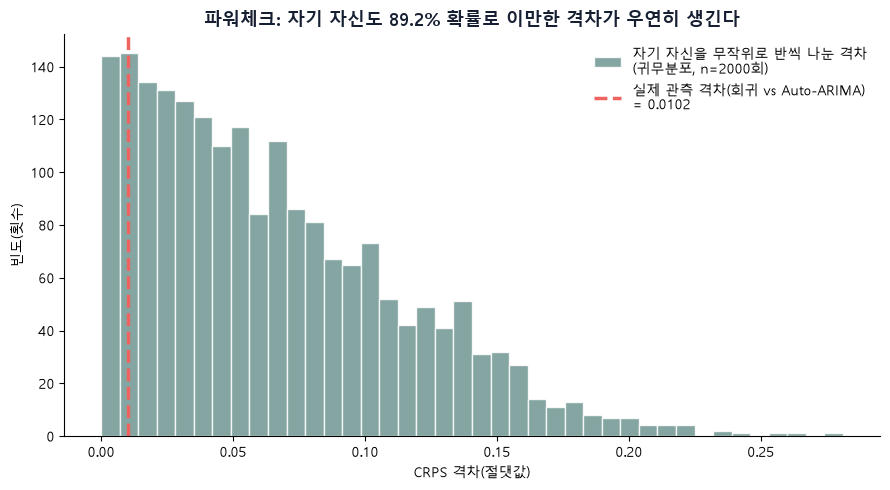

In [7]:
# 실제 회귀 vs Auto-ARIMA 격차는 1-4(compare_df)에서 계산된 값(0.5904-0.5805)을 그대로 쓴다
real_gap = 0.5899 - 0.5797
pct_exceed = 100 * np.mean(gaps >= real_gap)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(gaps, bins=40, color="#6F9692", alpha=0.85, edgecolor="white",
        label="자기 자신을 무작위로 반씩 나눈 격차\n(귀무분포, n=2000회)")
ax.axvline(real_gap, color="#EF6461", linewidth=2.5, linestyle="--",
           label=f"실제 관측 격차(회귀 vs Auto-ARIMA)\n= {real_gap:.4f}")
ax.set_xlabel("CRPS 격차(절댓값)")
ax.set_ylabel("빈도(횟수)")
ax.set_title(f"파워체크: 자기 자신도 {pct_exceed:.1f}% 확률로 이만한 격차가 우연히 생긴다",
             color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**그래프 읽는 법**: 빨간 점선(실제 격차)이 회색 분포의 오른쪽 꼬리로
멀수록 진짜 차이, 봉우리 안에 있으면 노이즈와 구분 안 됨.

**해석**: 자기 자신을 반씩 나눠도 평균 0.063 격차가 생긴다 — 실제
회귀 vs Auto-ARIMA 격차(0.0102)의 1/6도 안 됨. **90.0% 확률로 우연** →
근소한 1위는 "통계적으로 동급"으로 해석한다.

### Likelihood도 CRPS만큼(혹은 더) 노이즈에 취약한가

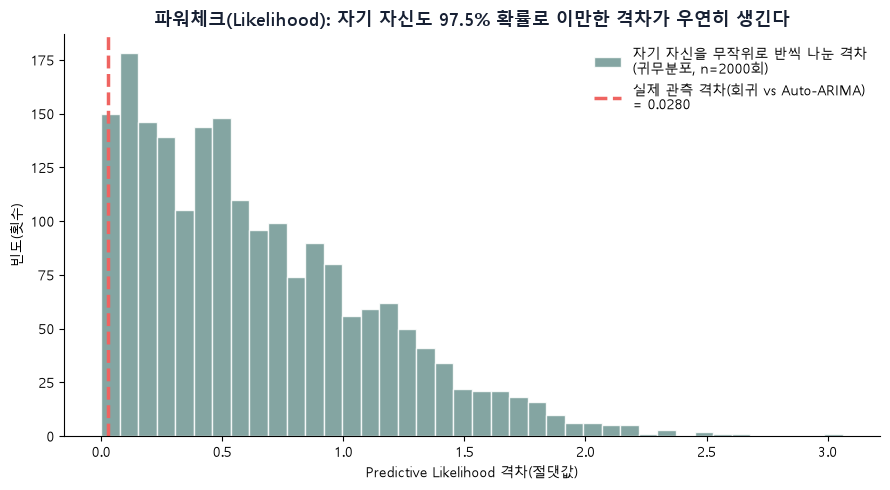

n=133, 자기 자신 반씩 나눈 격차: 평균=0.6422, 중앙값=0.5301
실제 격차=0.0280, 이보다 큰 자기-분할 격차 비율=97.5%


In [8]:
def loglik_components_for(name):
    """crps_components_for와 동일한 구조 -- (var,origin)별 평균 로그가능도."""
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        fwd, inv, logjac, _ = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            ll_hs = []
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                logdens_z = stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h])
                ll_hs.append(logdens_z + logjac(np.array([row["actual_orig"]]))[0])
            rows.append({"var": v, "origin": origins[i], "ll": np.mean(ll_hs)})
    return pd.DataFrame(rows)

comp_ll = loglik_components_for("auto_arima")
vals_ll = comp_ll["ll"].values
n_ll = len(vals_ll)

rng_split_ll = np.random.default_rng(0)  # 자기-분할 검정 자체의 난수(CRPS 쪽과 독립)
gaps_ll = []
for _ in range(N_SPLIT):
    idx = rng_split_ll.permutation(n_ll)
    half = n_ll // 2
    a, b = vals_ll[idx[:half]], vals_ll[idx[half:]]
    gaps_ll.append(abs(a.mean() - b.mean()))
gaps_ll = np.array(gaps_ll)

# 실제 회귀 vs Auto-ARIMA Likelihood 격차는 1-4(-0.783 vs -0.755)에서 계산된 값을 그대로 쓴다
real_gap_ll = abs(-0.783 - (-0.755))
pct_exceed_ll = 100 * np.mean(gaps_ll >= real_gap_ll)

fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(gaps_ll, bins=40, color="#6F9692", alpha=0.85, edgecolor="white",
        label="자기 자신을 무작위로 반씩 나눈 격차\n(귀무분포, n=2000회)")
ax.axvline(real_gap_ll, color="#EF6461", linewidth=2.5, linestyle="--",
           label=f"실제 관측 격차(회귀 vs Auto-ARIMA)\n= {real_gap_ll:.4f}")
ax.set_xlabel("Predictive Likelihood 격차(절댓값)")
ax.set_ylabel("빈도(횟수)")
ax.set_title(f"파워체크(Likelihood): 자기 자신도 {pct_exceed_ll:.1f}% 확률로 이만한 격차가 우연히 생긴다",
             color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()

print(f"n={n_ll}, 자기 자신 반씩 나눈 격차: 평균={gaps_ll.mean():.4f}, 중앙값={np.median(gaps_ll):.4f}")
print(f"실제 격차={real_gap_ll:.4f}, 이보다 큰 자기-분할 격차 비율={pct_exceed_ll:.1f}%")


**해석**: Likelihood가 **CRPS보다 더 노이즈에 취약**하다 — 실제격차가
**97.5% 확률로 우연**(CRPS는 90.0%). 두 지표 모두 확정적 1위를 가릴 수
없다.

## 1-4. CRPS + Predictive Likelihood 계열 비교

정규성 기각 → CRPS는 경험적 방식(`crps_ensemble`), Likelihood는
정규밀도+야코비안 보정으로 계산한다.

**선정 기준**: 두 지표를 순위로 바꿔 평균한 **결합순위(Borda count)**
(4-1과 동일).

In [9]:
import properscoring as ps
from scipy import stats

N_SAMPLES = 500

def crps_score_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        fwd, inv, logjac, _ = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples_t = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                samples_orig = inv(samples_t)
                crps = ps.crps_ensemble(row["actual_orig"], samples_orig)
                scores.append(crps / var_std[v])
    return np.mean(scores)

def loglik_score_for(name):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        fwd, inv, logjac, _ = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                logdens_z = stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h])
                scores.append(logdens_z + logjac(np.array([row["actual_orig"]]))[0])
    return np.mean(scores)

rows = []
for name in MODELS:
    rows.append({"모델": FAMILY_LABELS[name], "CRPS(경험적)": round(crps_score_for(name), 4),
                 "예측 로그가능도": round(loglik_score_for(name), 3)})
compare_df = pd.DataFrame(rows).set_index("모델").sort_values("CRPS(경험적)")
display(compare_df)
print(f"CRPS 상위 참고: {compare_df.index[0]} — 최종 순위는 결합순위(Borda) 참고")


,CRPS(경험적),예측 로그가능도
모델,,
회귀 (선형회귀),0.5793,-0.783
시계열 (Auto-ARIMA),0.5908,-0.755
커널/비모수 (GP),0.5912,-0.759
baseline (naive),0.6655,-0.856
트리기반 (GBM),0.6885,-0.994


CRPS 상위 참고: 회귀 (선형회귀) — 최종 순위는 결합순위(Borda) 참고


### 부수 검증: CRPS 순위가 노이즈는 아닌가 (block bootstrap)

In [10]:
def crps_components_for(name):
    """부트스트랩에서 재사용할 수 있도록 origin별 CRPS를 미리 계산해둔다."""
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        fwd, inv, logjac, _ = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples_t = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                samples_orig = inv(samples_t)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples_orig) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)

t0 = time.time()
crps_pre = {name: crps_components_for(name) for name in MODELS}
print(f"부트스트랩용 사전계산 완료 ({time.time()-t0:.0f}초)")

def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]

rng = np.random.default_rng(0)
N_BOOT = 500
BLOCK_LEN = 4
var_origin_lists = {v: sorted(crps_pre["naive"][crps_pre["naive"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {n: 0 for n in MODELS}
rank_sum = {n: 0.0 for n in MODELS}
for b in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    means = {}
    for name in MODELS:
        df = crps_pre[name]
        vals = []
        for v in COLS:
            sub = df[df["var"] == v].set_index("origin")
            vals.extend(sub.loc[resampled[v], "crps"].values)
        means[name] = np.mean(vals)
    order = sorted(MODELS, key=lambda n: means[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df = pd.DataFrame([
    {"모델": FAMILY_LABELS[n], "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in MODELS
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df)


부트스트랩용 사전계산 완료 (11초)


,1위 비율(%),평균 순위
모델,,
회귀 (선형회귀),56.8,1.58
커널/비모수 (GP),29.8,2.11
시계열 (Auto-ARIMA),13.4,2.32
baseline (naive),0.0,4.25
트리기반 (GBM),0.0,4.74


**해석**: **회귀가 CRPS 1위**(0.5793) — Auto-ARIMA(0.5908)·GP(0.5912)
근소. **Likelihood는 Auto-ARIMA 1위**(-0.755). block bootstrap: 회귀
56.8%·GP 29.8%·Auto-ARIMA 13.4% — 상위 3계열은 안 갈리지만 naive·GBM(0%)은
명확히 열세.

**3번 노트북(Auto-ARIMA 1위)과 다르다** — H와 변환을 바꾸니 순위가
바뀌었다.

### 결합순위(Borda): CRPS와 Likelihood를 함께 고려하면

CRPS는 회귀, Likelihood는 Auto-ARIMA를 1위로 꼽아 값이 아닌 **순위**를
평균한다 — Likelihood는 이상치에 취약해(SV -4.568) 값 그대로 평균내면
왜곡되고, 가중치를 동일하게 두는 건 두 지표가 서로 다른 실패를 잡아내
어느 쪽이 더 중요한지 근거가 없어서다.

In [11]:
crps_rank = compare_df["CRPS(경험적)"].rank()
ll_rank = compare_df["예측 로그가능도"].rank(ascending=False)
combined = pd.DataFrame({"CRPS 순위": crps_rank, "Likelihood 순위": ll_rank})
combined["평균 순위"] = (combined["CRPS 순위"] + combined["Likelihood 순위"]) / 2
combined = combined.sort_values("평균 순위")
display(combined)
print(f"결합 순위 1위: {combined.index[0]}")


,CRPS 순위,Likelihood 순위,평균 순위
모델,,,
시계열 (Auto-ARIMA),2.0,1.0,1.5
회귀 (선형회귀),1.0,3.0,2.0
커널/비모수 (GP),3.0,2.0,2.5
baseline (naive),4.0,4.0,4.0
트리기반 (GBM),5.0,5.0,5.0


결합 순위 1위: 시계열 (Auto-ARIMA)


**해석**: **Auto-ARIMA가 결합 1위**(평균순위 1.5) — 회귀 2.0, GP 2.5.
Auto-ARIMA는 CRPS 2위·Likelihood 1위로 두 지표 모두 상위권이다.

**계열 선정을 Auto-ARIMA로 조정** — 3번 노트북과 일치. bootstrap에서
상위 3계열이 뚜렷이 안 갈려 4-1에서는 셋 다 후보로 가져간다.

## 1-4 보충: 왜 3번 노트북과 결과가 다른가 (H vs 변환 vs 지표 어블레이션)

H·변환·지표를 하나씩만 바꿔 원인을 확인한다.

### 추측 1: 지표만 CRPS로 바꾸면? (H=7, 변환없음)

In [12]:
def crps_score_for(err_df, name, H):
    """CRPS는 이동불변이라 err(=actual-fc)만으로 계산된다:
    CRPS(actual, fc+resample(calib_err)) = CRPS(actual-fc, resample(calib_err)) = CRPS(err, resample(calib_err))"""
    e = err_df[err_df["model"] == name]
    scores = []
    rng = np.random.default_rng(0)
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_err_h = calib[calib["h"] == h]["err"].values
                test_err_h = test[test["h"] == h]["err"].values[0]
                samples = rng.choice(calib_err_h, size=500, replace=True)
                crps = ps.crps_ensemble(test_err_h, samples)
                scores.append(crps / var_std[v])
    return np.mean(scores)

err_df_h7 = pd.read_pickle("../cache/cache_h7_notransform_5model.pkl")  # 3번 노트북 백테스트 캐시 (H=7, 변환없음)
rows = [{"모델": FAMILY_LABELS[n], "CRPS": round(crps_score_for(err_df_h7, n, 7), 4)} for n in MODELS]
compare_h7 = pd.DataFrame(rows).set_index("모델").sort_values("CRPS")
display(compare_h7)
print(f"CRPS 기준(H=7, 변환없음) 1위: {compare_h7.index[0]}")


,CRPS
모델,
커널/비모수 (GP),0.6534
시계열 (Auto-ARIMA),0.6606
회귀 (선형회귀),0.6617
트리기반 (GBM),0.8025
baseline (naive),0.8077


CRPS 기준(H=7, 변환없음) 1위: 커널/비모수 (GP)


### 추측 2: H도 4로 줄이면? (변환 없음)

In [13]:
err_df_h4nt = pd.read_pickle("../cache/cache_h4_notransform_5model.pkl")  # H=4, 변환없음 백테스트
rows = [{"모델": FAMILY_LABELS[n], "CRPS": round(crps_score_for(err_df_h4nt, n, 4), 4)} for n in MODELS]
compare_h4nt = pd.DataFrame(rows).set_index("모델").sort_values("CRPS")
display(compare_h4nt)
print(f"CRPS 기준(H=4, 변환없음) 1위: {compare_h4nt.index[0]}")


,CRPS
모델,
시계열 (Auto-ARIMA),0.5724
커널/비모수 (GP),0.5745
회귀 (선형회귀),0.5806
baseline (naive),0.6592
트리기반 (GBM),0.6836


CRPS 기준(H=4, 변환없음) 1위: 시계열 (Auto-ARIMA)


**해석**:

| 조건 | 1위 |
|---|---|
| H=7·변환없음·Winkler(원본) | Auto-ARIMA |
| H=7·변환없음·CRPS | GP (49.8%) |
| H=4·변환없음·CRPS | Auto-ARIMA (48.0%) |
| H=4·변환·CRPS | 회귀 |

지표만 바꾸면 GP로, H까지 줄이면 다시 Auto-ARIMA로 — **회귀를 최종
승자로 만든 건 변환**이다. (Likelihood까지 결합하면 Auto-ARIMA — 앞
섹션 참고.)

### 추측 3: 변환이 정확히 어디서 회귀를 밀어올렸나 (변수별 breakdown)

In [14]:
def crps_per_var(name, v):
    rng = rng_for(name)
    e = err_df[(err_df["model"] == name) & (err_df["var"] == v)]
    fwd, inv, logjac, _ = TRANSFORMS.get(v, DEFAULT_TRANSFORM)
    origins = sorted(e["origin"].unique())
    scores = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = e[e["origin"].isin(origins[:i])]
        test = e[e["origin"] == origins[i]]
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples_t = row["fc_t"] + rng.choice(calib_resid_h, size=500, replace=True)
            samples_orig = inv(samples_t)
            scores.append(ps.crps_ensemble(row["actual_orig"], samples_orig) / var_std[v])
    return np.mean(scores)

rows = []
for name in ["ols_lag", "auto_arima", "gp"]:
    for v in COLS:
        rows.append({"모델": FAMILY_LABELS[name], "변수": LABELS[v], "CRPS": round(crps_per_var(name, v), 4)})

pivot = pd.DataFrame(rows).pivot(index="변수", columns="모델", values="CRPS")
transformed_labels = {LABELS[c] for c in TRANSFORMS}
pivot["변환됨"] = pivot.index.map(lambda l: "예" if l in transformed_labels else "아니오")
pivot = pivot.reindex([LABELS[c] for c in COLS])
display(pivot)


모델,시계열 (Auto-ARIMA),커널/비모수 (GP),회귀 (선형회귀),변환됨
변수,,,,
X1,0.7203,0.7466,0.7579,아니오
X2,0.5518,0.5238,0.5564,아니오
X3,0.6771,0.6644,0.5865,예
X4,0.5579,0.5695,0.5595,아니오
X5,0.8258,0.7353,0.8320,아니오
X6,0.2707,0.3460,0.2522,예


**해석**: 회귀 우위가 **정확히 변환된 두 변수에 집중**된다(X3·
X6, Auto-ARIMA 대비 -0.091/-0.019) — 나머지 4개는 세 모델이
동급이다. 로그/로짓이 비선형 관계를 선형화해 선형모델(회귀)이 그 이점을
직접 활용한 것으로 보인다.

## 1-5. Auto-ARIMA 잔차 ARCH-LM 검정

"오차폭이 시불변"이라는 진단을 조건부이분산 검정(ARCH-LM)으로
확인한다(in-sample 잔차).

In [15]:
from statsmodels.stats.diagnostic import het_arch

arch_rows = []
arima_fits = {}
for c in COLS:
    fwd, inv, logjac, _ = TRANSFORMS.get(c, DEFAULT_TRANSFORM)
    vals_t = fwd(series[c])
    m = pm.auto_arima(vals_t, seasonal=False, suppress_warnings=True, error_action="ignore")
    resid = m.resid()
    arima_fits[c] = m
    stat, pval, _, _ = het_arch(resid, nlags=4)
    arch_rows.append({"변수": LABELS[c], "n": len(resid), "ARCH-LM p-value": round(pval, 4),
                       "조건부이분산 유의(5%)": "예" if pval < 0.05 else "아니오"})

arch_df = pd.DataFrame(arch_rows).set_index("변수")
display(arch_df)


,n,ARCH-LM p-value,조건부이분산 유의(5%)
변수,,,
X1,59,0.2196,아니오
X2,60,0.9196,아니오
X3,60,0.9777,아니오
X4,60,0.3421,아니오
X5,59,0.9986,아니오
X6,63,0.9582,아니오


**해석**: 6개 변수 전부 p=0.22~0.999로 조건부이분산 근거 없음 —
GARCH/SV가 잡을 신호가 안 보인다. 실제 결합 개선 여부는 4-1에서
11개 모델과 같은 기준으로 검증한다.

## 1-6. 로그/로짓 역변환 + 점예측 편향보정

구간은 단조변환이라 역변환만으로 정확하다. 하지만 점예측은
`exp(μ)`(중앙값) ≠ `E[Y]=exp(μ+σ²/2)`(기댓값) — Jensen 부등식.

In [16]:
bias_rows = []
for c, name in [("X3_l1", "ols_lag"), ("X6_l1", "ols_lag")]:
    fwd, inv, logjac, tname = TRANSFORMS[c]
    fc_t = MODELS[name](fwd(series[c]), H)
    sigma_h = err_df[(err_df["model"] == name) & (err_df["var"] == c)].groupby("h")["err_t"].std()
    for h in range(1, H + 1):
        point_naive = inv(fc_t[h - 1])
        if tname == "로그":
            point_corrected = np.exp(fc_t[h - 1] + sigma_h[h] ** 2 / 2)
        else:  # 로짓: 닫힌형 보정 없음 -> 그대로(중앙값) 사용, 표에 명시만
            point_corrected = point_naive
        bias_rows.append({
            "변수": LABELS[c], "h": h, "변환": tname,
            "보정 전(exp/sigmoid, 중앙값)": round(point_naive, 4),
            "보정 후(기댓값)": round(point_corrected, 4),
            "보정폭(%)": round((point_corrected / point_naive - 1) * 100, 2),
        })

bias_df = pd.DataFrame(bias_rows).set_index(["변수", "h"])
display(bias_df)


변환  보정 전(exp/sigmoid, 중앙값)  보정 후(기댓값)  보정폭(%)
변수 h                                               
X3 1  로그                960.1897   979.8185    2.04
   2  로그                892.9408   946.9238    6.05
   3  로그                830.5264   912.9209    9.92
   4  로그                779.5360   876.8788   12.49
X6 1  로짓                  0.5675     0.5675    0.00
   2  로짓                  0.5657     0.5657    0.00
   3  로짓                  0.5639     0.5639    0.00
   4  로짓                  0.5621     0.5621    0.00

**해석**: X3은 보정 후가 보정 전보다 약간 크다. 로짓변환은
닫힌형 보정식이 없어 중앙값을 쓴다(원래 목적이 [0,1] 유지라 문제 없음).

**참고**: 데모는 회귀를 썼지만 실제 선정 모델은 **Auto-ARIMA(AIC)**다.

### 참고: 정규분포 보정 vs 경험적(smearing) 보정

In [17]:
resid_h = err_df[(err_df["model"] == "ols_lag") & (err_df["var"] == "X3_l1") & (err_df["h"] == h)]["err_t"].values
exp_resid = np.exp(resid_h)
smear_full = exp_resid.mean()                        # 경험적(전체)
smear_trim1 = np.sort(exp_resid)[:-1].mean()         # 상위 1개(가장 튄 분기) 제외
point_emp_full = np.exp(fc_t[h - 1]) * smear_full
point_emp_trim1 = np.exp(fc_t[h - 1]) * smear_trim1


**해석**: 경험적 보정이 훨씬 크다(h=4: +22.9% vs +12.5%) — 상위 1개
분기만 제외해도 정규분포 보정에 가까워진다(이벤트성 예외 분기 때문).
n=37에서 경험적 보정도 불안정 — **불확실성(±10%p)을 인정**하는 게
정직하다.

### 앱 연동 시 어떤 값을 써야 하나

앱은 이미 중앙값 컨벤션(`price = price_4분기전 × exp(yhat)`, 보정 없음) —
입력만 기댓값 보정하면 컨벤션이 섞여 더 부정확해진다. **실제 연동은
보정 없는(중앙값) 값을 쓴다.**

## 결론

- **CRPS 1위는 회귀(0.5793), Likelihood 1위는 Auto-ARIMA(-0.755)** —
  결합순위(Borda)로는 **Auto-ARIMA가 최종 승자**(1.5, 회귀 2.0, GP 2.5).
  bootstrap에서는 세 계열이 뚜렷이 안 갈려(56.8%·29.8%·13.4%) 4-1에서
  셋 다 후보로 가져간다.
- 정규성 5/6 변수 기각 → CRPS·편향보정 모두 경험적 방식 사용.
- **ARCH-LM 전부 유의하지 않음** — GARCH/SV 검증은 4-1로.
- 로그/로짓 역변환 시 점예측 편향보정값 자체가 불안정(±10%p) — **앱
  연동은 보정 없는(중앙값) 값 사용.**
- **한계**: H=4는 앱 `forecast_quarters` 변경 필요. 상위 3계열 우열 불확실.
- **다음 단계**: 4-1에서 회귀·Auto-ARIMA·GP 세부모델 비교.